# Food Classification: Good / Moderate / Harm

Classifies packaged-food photos into three classes using image features plus text read off the package.

**Pipeline**

1. ResNet50 (2048 features) + GoogLeNet (1024 features) = 3072 CNN features
2. OCR with Tesseract -> 15 numbers (nutrition values, keyword counts)
3. Join them: 3087 features, then scale + PCA (256) on the CNN part
4. Train KNN, XGBoost, Decision Tree, SVM and Random Forest
5. Stack them, with AdaBoost as the meta learner

**How saving works**

Everything slow is saved to Google Drive in `Food_Classification1/saved_models/` as soon as it finishes:
the extracted features, the preprocessor, each base model, and the final stacked model. Every cell checks for its saved file first, so after a disconnect you just run the notebook from the top again. It loads what it finds and only trains what's missing.

**Before you start**

* Runtime -> Change runtime type -> pick a GPU (T4 is fine). It makes the CNN step much faster.
* The dataset should be in Drive at `MyDrive/Food_Classification1/dataset/` with `Good/`, `Moderate/` and `Harm/` inside.

## 1. Setup

In [1]:
# tesseract is the OCR program itself, pytesseract is just the python wrapper
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install pytesseract

In [2]:
import os
import re
import json
import time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from PIL import Image
from joblib import Parallel, delayed

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

import pytesseract

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from xgboost import XGBClassifier

# let each tesseract call use one thread, we already run several in parallel
os.environ["OMP_THREAD_LIMIT"] = "1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Paths and dataset

The images are copied from Drive to Colab's local disk once per session, because reading ~10,000 files straight from Drive is slow. Features and models still get saved back to Drive.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
PROJECT_DIR = "/content/drive/MyDrive/Food_Classification1"
DRIVE_DATASET = os.path.join(PROJECT_DIR, "dataset")
SAVE_DIR = os.path.join(PROJECT_DIR, "saved_models")      # everything permanent goes here
os.makedirs(SAVE_DIR, exist_ok=True)

DATASET_DIR = "/content/dataset"                           # local copy (fast to read)

CLASS_NAMES = ["Good", "Moderate", "Harm"]   # position in this list = label number
RANDOM_STATE = 42
TARGET_ACCURACY = 0.80

# set to True only if you changed the dataset and want to rebuild everything
FORCE_RETRAIN = False

In [5]:
if not os.path.exists(os.path.join(DATASET_DIR, "Good")):
    print("Copying dataset from Drive, this takes a few minutes...")
    !cp -r "$DRIVE_DATASET" /content/dataset
else:
    print("Dataset already copied")

print(os.listdir(DATASET_DIR))

Copying dataset from Drive, this takes a few minutes...
['Moderate', 'Harm', 'Good']


In [6]:
def get_paths_and_labels(dataset_dir):
    paths, labels = [], []
    for label, name in enumerate(CLASS_NAMES):
        folder = os.path.join(dataset_dir, name)
        # sorted so the order is the same every run (cached features depend on it)
        for f in sorted(os.listdir(folder)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(folder, f))
                labels.append(label)
    return paths, np.array(labels)


image_paths, labels = get_paths_and_labels(DATASET_DIR)
print("Total images:", len(image_paths))
for i, name in enumerate(CLASS_NAMES):
    print(f"  {name}: {(labels == i).sum()}")

Total images: 9867
  Good: 4687
  Moderate: 2410
  Harm: 2770


## 3. Feature extraction

### 3.1 CNN features (ResNet50 and GoogLeNet)

Both networks are pretrained on ImageNet and used as they are, with no training. The final classification layer is replaced with `Identity`, so the output is the feature vector from the layer just before it.

Images are squashed to 224x224 instead of centre-cropped, because product photos are tall and a crop would cut the label off.

In [7]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


class ImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # handles grayscale / alpha PNGs
        return transform(img)


def extract_cnn_features(model, paths, name, batch_size=32):
    model.fc = nn.Identity()
    model = model.to(device).eval()

    loader = DataLoader(ImageDataset(paths), batch_size=batch_size, shuffle=False, num_workers=2)

    out = []
    with torch.no_grad():
        for i, batch in enumerate(loader):
            out.append(model(batch.to(device)).cpu().numpy())
            if i % 20 == 0:
                print(f"  {name}: batch {i + 1}/{len(loader)}")
    return np.vstack(out).astype(np.float32)


def extract_resnet50_features(paths):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    return extract_cnn_features(model, paths, "ResNet50")      # (N, 2048)


def extract_googlenet_features(paths):
    model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)
    return extract_cnn_features(model, paths, "GoogLeNet")     # (N, 1024)

### 3.2 OCR features

Tesseract reads the text on the package, then we turn it into 15 numbers: nutrition values (calories, fat, sodium, sugar), whether an ingredient list exists, and counts of sugar / fat / salt / healthy / additive / processed-food keywords.

Many photos are front-of-pack shots with little readable text. For those the OCR features are mostly zero and the CNN features do the work.

In [8]:
OCR_FEATURE_NAMES = [
    "text_length", "word_count",
    "has_nutrition_label", "calories", "fat_g", "sodium_mg", "sugar_g",
    "has_ingredients", "ingredient_count",
    "sugar_words", "fat_words", "salt_words",
    "healthy_words", "additive_words", "processed_words",
]


def word_pattern(words):
    # \b so "ham" doesn't match inside "shampoo"
    return re.compile(r"\b(" + "|".join(words) + r")\b")


SUGAR = word_pattern(["sugar", "sugars", "syrup", "candy", "chocolate", "cookie", "cookies",
                      "cake", "sweet", "dessert", "caramel", "toffee", "frosting", "cola",
                      "soda", "fructose", "dextrose", "sweetened", "glucose"])
FAT = word_pattern(["fried", "butter", "bacon", "cheese", "mayo", "mayonnaise", "ranch",
                    "sausage", "spam", "lard", "cream", "creamy", "oil", "shortening",
                    "hydrogenated", "saturated"])
SALT = word_pattern(["salt", "salted", "sodium", "chips", "pickle", "pickled", "ham",
                     "jerky", "bouillon", "brine", "cured"])
HEALTHY = word_pattern(["organic", "whole", "grain", "wheat", "natural", "fiber", "protein",
                        "fresh", "vegetable", "vegetables", "fruit", "fruits", "bean", "beans",
                        "oat", "oats", "lean", "light", "lite", "unsweetened", "low", "free",
                        "vitamin", "vitamins"])
ADDITIVE = word_pattern(["artificial", "preservative", "preservatives", "colors", "color",
                         "flavors", "flavor", "msg", "nitrite", "nitrate", "benzoate",
                         "sorbate", "bht", "bha", "modified", "starch", "dye"])
PROCESSED = word_pattern(["instant", "microwave", "frozen", "canned", "ready", "mix", "snack",
                          "nuggets", "dressing", "sauce", "pizza", "burger", "noodles"])

# nutrition label numbers, e.g. "calories 230", "fat 8g", "sodium 160mg"
CALORIES_RE = re.compile(r"calories\D{0,10}(\d{1,4})")
FAT_RE = re.compile(r"fat\D{0,10}(\d{1,3}(?:\.\d)?)\s*g")
SODIUM_RE = re.compile(r"sodium\D{0,10}(\d{1,4})\s*mg")
SUGAR_RE = re.compile(r"sugars?\D{0,10}(\d{1,3}(?:\.\d)?)\s*g")


def read_number(pattern, text, max_value):
    m = pattern.search(text)
    if m is None:
        return 0.0
    value = float(m.group(1))
    # OCR misreads digits sometimes, so drop impossible values
    return value if value <= max_value else 0.0


def read_text(path):
    img = Image.open(path).convert("L")
    img = img.resize((img.width * 2, img.height * 2))   # bigger text is easier for tesseract
    return pytesseract.image_to_string(img).lower()


def text_to_features(text):
    text = re.sub(r"[^a-z0-9.,:%()/\s-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    words = [w for w in re.findall(r"[a-z]+", text) if len(w) >= 3]

    calories = read_number(CALORIES_RE, text, 1000)
    fat_g = read_number(FAT_RE, text, 100)
    sodium_mg = read_number(SODIUM_RE, text, 3000)
    sugar_g = read_number(SUGAR_RE, text, 100)
    has_label = 1.0 if ("nutrition facts" in text or calories > 0) else 0.0

    has_ingredients = 1.0 if "ingredients" in text else 0.0
    ingredient_count = 0.0
    if has_ingredients:
        after = text.split("ingredients", 1)[1]
        ingredient_count = float(min(after.count(",") + 1, 60))   # roughly one per comma

    return [len(text), len(words), has_label, calories, fat_g, sodium_mg, sugar_g,
            has_ingredients, ingredient_count,
            len(SUGAR.findall(text)), len(FAT.findall(text)), len(SALT.findall(text)),
            len(HEALTHY.findall(text)), len(ADDITIVE.findall(text)), len(PROCESSED.findall(text))]


def ocr_one_image(path):
    try:
        return text_to_features(read_text(path))
    except Exception as e:
        print(f"  OCR failed for {path}: {e}")
        return [0.0] * len(OCR_FEATURE_NAMES)


def extract_ocr_features(paths):
    pytesseract.get_tesseract_version()   # fails early if tesseract isn't installed
    rows = Parallel(n_jobs=-1, verbose=5)(delayed(ocr_one_image)(p) for p in paths)
    return np.array(rows, dtype=np.float32)

### 3.3 Run the extraction

This is the slow part. Each result is saved as a `.npy` file in Drive the moment it finishes, so if the session dies halfway you only lose the step that was running. Re-running the cell loads the finished ones from disk.

In [9]:
def load_or_extract(file_name, extract_fn, paths):
    file_path = os.path.join(SAVE_DIR, file_name)
    if os.path.exists(file_path) and not FORCE_RETRAIN:
        feats = np.load(file_path)
        if feats.shape[0] == len(paths):
            print(f"Loaded {file_name} {feats.shape}")
            return feats
        print(f"{file_name} doesn't match the dataset size, recomputing")
    print(f"Extracting {file_name} ...")
    feats = extract_fn(paths)
    np.save(file_path, feats)
    print(f"Saved {file_name} {feats.shape}")
    return feats


start = time.time()
resnet_feats = load_or_extract("resnet50_features.npy", extract_resnet50_features, image_paths)
googlenet_feats = load_or_extract("googlenet_features.npy", extract_googlenet_features, image_paths)
ocr_feats = load_or_extract("ocr_features.npy", extract_ocr_features, image_paths)
print(f"Done in {(time.time() - start) / 60:.1f} min")

Loaded resnet50_features.npy (9867, 2048)
Loaded googlenet_features.npy (9867, 1024)
Loaded ocr_features.npy (9867, 15)
Done in 0.1 min


## 4. Feature fusion and train/val/test split

The CNN features are 3072 columns wide and the OCR features are only 15, so the model preprocessing handles them in separate branches.

Split is 70 / 15 / 15, stratified. The test set is only used for the final numbers, never for tuning.

In [10]:
N_CNN = 3072   # 2048 + 1024


def fuse_cnn(resnet, googlenet):
    return np.concatenate([resnet, googlenet], axis=1)


def fuse_all(cnn, ocr):
    return np.concatenate([cnn, ocr], axis=1)

In [11]:
X = fuse_all(fuse_cnn(resnet_feats, googlenet_feats), ocr_feats)
y = labels
print("Combined features:", X.shape)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print(f"Train: {len(y_train)}  Val: {len(y_val)}  Test: {len(y_test)}")

Combined features: (9867, 3087)
Train: 6906  Val: 1480  Test: 1481


## 5. Scaling + PCA

* CNN columns: standardise, then PCA down to 256 components.
* OCR columns: just standardise. Putting them through PCA with 3072 CNN columns would bury them.

The preprocessor is fitted on the training set only. Validation, test and new images just get transformed, otherwise information leaks from the test set.

It's saved to Drive after fitting. It has to be the same object later when you predict new images, so don't refit it separately.

In [12]:
def build_preprocessor(n_total, pca_components=256):
    cnn_cols = list(range(0, N_CNN))
    ocr_cols = list(range(N_CNN, n_total))

    cnn_branch = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=pca_components, random_state=RANDOM_STATE)),
    ])
    return ColumnTransformer([
        ("cnn", cnn_branch, cnn_cols),
        ("ocr", StandardScaler(), ocr_cols),
    ])


PREPROCESSOR_FILE = os.path.join(SAVE_DIR, "preprocessor.joblib")

if os.path.exists(PREPROCESSOR_FILE) and not FORCE_RETRAIN:
    preprocessor = joblib.load(PREPROCESSOR_FILE)
    print("Loaded saved preprocessor")
    X_train = preprocessor.transform(X_train)
else:
    preprocessor = build_preprocessor(X.shape[1], pca_components=256)
    X_train = preprocessor.fit_transform(X_train)
    joblib.dump(preprocessor, PREPROCESSOR_FILE)
    print("Fitted and saved preprocessor")

X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)
print("After scaling + PCA:", X_train.shape[1], "features per image")

Loaded saved preprocessor
After scaling + PCA: 271 features per image


## 6. Base classifiers

Each one has limits on depth, leaf size, K or C so it doesn't just memorise the training set.

Every model is saved to Drive right after it's trained, and loaded from there next time instead of being trained again.

In [13]:
def get_knn():
    return KNeighborsClassifier(n_neighbors=15, weights="uniform", metric="euclidean", n_jobs=-1)


def get_xgboost():
    return XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.5, reg_lambda=2.0,
        objective="multi:softprob", eval_metric="mlogloss",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
    )


def get_decision_tree():
    return DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=10,
        class_weight="balanced", random_state=RANDOM_STATE,
    )


def get_svm():
    # probability=True is needed because stacking uses the class probabilities
    return SVC(kernel="rbf", C=1.0, gamma="scale", probability=True,
               class_weight="balanced", random_state=RANDOM_STATE)


def get_random_forest():
    return RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=3,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    )

In [14]:
def accuracy_of(model, X, y):
    return accuracy_score(y, model.predict(X))


def diagnose_fit(name, train_acc, val_acc, test_acc, target=0.80):
    gap = train_acc - test_acc
    print(f"{name:<18} train={train_acc:.4f}  val={val_acc:.4f}  test={test_acc:.4f}  gap={gap:.4f}")
    if gap > 0.10:
        print("   -> gap over 10 points, probably overfitting")
    elif train_acc < target and test_acc < target:
        print("   -> low on both, probably underfitting")
    else:
        print("   -> looks fine")


base_models = {
    "KNN": get_knn,
    "XGBoost": get_xgboost,
    "Decision Tree": get_decision_tree,
    "SVM": get_svm,
    "Random Forest": get_random_forest,
}


def load_or_train(file_name, build_fn, X_fit, y_fit):
    path = os.path.join(SAVE_DIR, file_name)
    if os.path.exists(path) and not FORCE_RETRAIN:
        print(f"Loaded {file_name}")
        return joblib.load(path)
    print(f"Training {file_name} ...")
    model = build_fn()
    model.fit(X_fit, y_fit)
    joblib.dump(model, path)
    print(f"Saved {file_name}")
    return model


for name, build_fn in base_models.items():
    file_name = "base_" + name.lower().replace(" ", "_") + ".joblib"
    model = load_or_train(file_name, build_fn, X_train, y_train)
    diagnose_fit(name,
                 accuracy_of(model, X_train, y_train),
                 accuracy_of(model, X_val, y_val),
                 accuracy_of(model, X_test, y_test))

Loaded base_knn.joblib
KNN                train=0.6380  val=0.5872  test=0.5692  gap=0.0688
   -> low on both, probably underfitting
Loaded base_xgboost.joblib
XGBoost            train=0.8727  val=0.5716  test=0.5739  gap=0.2988
   -> gap over 10 points, probably overfitting
Loaded base_decision_tree.joblib
Decision Tree      train=0.5501  val=0.4372  test=0.4396  gap=0.1105
   -> gap over 10 points, probably overfitting
Loaded base_svm.joblib
SVM                train=0.8630  val=0.5764  test=0.5814  gap=0.2817
   -> gap over 10 points, probably overfitting
Loaded base_random_forest.joblib
Random Forest      train=0.9975  val=0.5439  test=0.5631  gap=0.4344
   -> gap over 10 points, probably overfitting


Random Forest will show close to 100% train accuracy no matter what, so go by its validation and test numbers.

## 7. Stacking with AdaBoost

How it works:

1. Split the training data into 5 folds.
2. Each base model trains on 4 folds and predicts class probabilities for the 5th. After 5 rounds every training image has probabilities from models that never saw it.
3. That gives 5 models x 3 classes = 15 numbers per image. AdaBoost (the meta learner) trains on those.
4. Finally the base models are refit on the whole training set for use on new images.

`StackingClassifier` does all of this for us. It takes a few minutes, and it's saved to Drive as `final_model.joblib` when done. Once that file exists, this cell just loads it.

In [15]:
def get_adaboost():
    weak = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
    return AdaBoostClassifier(estimator=weak, n_estimators=100,
                              learning_rate=0.5, random_state=RANDOM_STATE)


def build_stacking_model():
    estimators = [
        ("knn", get_knn()),
        ("xgb", get_xgboost()),
        ("dt", get_decision_tree()),
        ("svm", get_svm()),
        ("rf", get_random_forest()),
    ]
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return StackingClassifier(
        estimators=estimators,
        final_estimator=get_adaboost(),
        cv=folds,
        stack_method="predict_proba",
        passthrough=False,   # meta learner only sees the 15 probabilities
        n_jobs=1,
    )


final_model = load_or_train("final_model.joblib", build_stacking_model, X_train, y_train)

train_acc = accuracy_of(final_model, X_train, y_train)
val_acc = accuracy_of(final_model, X_val, y_val)
test_acc = accuracy_of(final_model, X_test, y_test)
diagnose_fit("Stacking+AdaBoost", train_acc, val_acc, test_acc, TARGET_ACCURACY)

Loaded final_model.joblib
Stacking+AdaBoost  train=0.8734  val=0.6101  test=0.5982  gap=0.2752
   -> gap over 10 points, probably overfitting


## 8. Final evaluation on the test set

              precision    recall  f1-score   support

        Good     0.6484    0.7727    0.7051       704
    Moderate     0.4375    0.2909    0.3494       361
        Harm     0.5896    0.5697    0.5795       416

    accuracy                         0.5982      1481
   macro avg     0.5585    0.5444    0.5447      1481
weighted avg     0.5805    0.5982    0.5831      1481

Macro F1: 0.5447


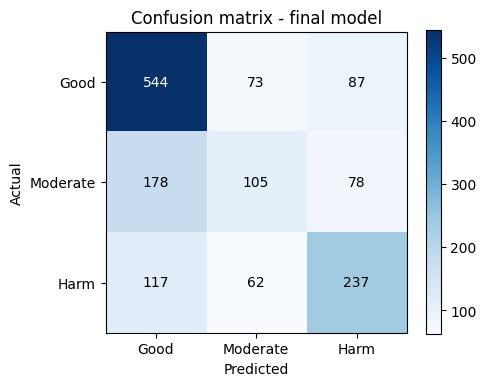


FINAL TEST ACCURACY = 59.82%
Below 80% - see the tips at the bottom of this notebook.


In [16]:
preds = final_model.predict(X_test)

print(classification_report(y_test, preds, target_names=CLASS_NAMES, digits=4))
print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))

matrix = confusion_matrix(y_test, preds)

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")
plt.title("Confusion matrix - final model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(range(3), CLASS_NAMES)
plt.yticks(range(3), CLASS_NAMES)
for r in range(3):
    for c in range(3):
        color = "white" if matrix[r, c] > matrix.max() / 2 else "black"
        plt.text(c, r, matrix[r, c], ha="center", va="center", color=color)
plt.colorbar()
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

# keep the numbers on Drive too
with open(os.path.join(SAVE_DIR, "results.json"), "w") as f:
    json.dump({"train_acc": train_acc, "val_acc": val_acc, "test_acc": test_acc,
               "macro_f1": f1_score(y_test, preds, average="macro")}, f, indent=2)

print(f"\nFINAL TEST ACCURACY = {test_acc * 100:.2f}%")
if test_acc > TARGET_ACCURACY:
    print("Reached the 80% target.")
else:
    print("Below 80% - see the tips at the bottom of this notebook.")

## 9. Check what's saved in Drive

Nothing to do here, the files were already saved as each step finished. This just lists them. If the models are listed, you never have to train them again.

In [17]:
for f in sorted(os.listdir(SAVE_DIR)):
    size_mb = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1e6
    print(f"{f:<32} {size_mb:8.1f} MB")

base_decision_tree.joblib             0.0 MB
base_knn.joblib                       7.5 MB
base_random_forest.joblib            21.4 MB
base_svm.joblib                      13.9 MB
base_xgboost.joblib                   1.5 MB
final_model.joblib                   44.5 MB
googlenet_features.npy               40.4 MB
ocr_features.npy                      0.6 MB
preprocessor.joblib                   3.3 MB
resnet50_features.npy                80.8 MB
results.json                          0.0 MB


## 10. Predict a new image

Run the cell, then choose an image from your computer.

**Predict-only session** (you just want to classify images and don't care about retraining): run section 1 (setup and imports), the "mount Drive" and "paths" cells in section 2, the two definition cells in section 3 (CNN and OCR extractors), and the `fuse_cnn` / `fuse_all` definitions in section 4. Then run the cells below. You can skip the dataset copy, the feature extraction, the splitting and all the training, since the saved models get loaded from Drive.

In [18]:
def predict_image(image_path):
    pre = joblib.load(os.path.join(SAVE_DIR, "preprocessor.joblib"))
    model = joblib.load(os.path.join(SAVE_DIR, "final_model.joblib"))

    paths = [image_path]   # extractors expect a list
    x = fuse_all(fuse_cnn(extract_resnet50_features(paths),
                          extract_googlenet_features(paths)),
                 extract_ocr_features(paths))
    x = pre.transform(x)

    probs = model.predict_proba(x)[0]
    return CLASS_NAMES[int(np.argmax(probs))], probs

Saving eggless-vanilla-cake-mix-1000x1000.webp to eggless-vanilla-cake-mix-1000x1000.webp
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 127MB/s]


  ResNet50: batch 1/1
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 159MB/s]


  GoogLeNet: batch 1/1


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



eggless-vanilla-cake-mix-1000x1000.webp -> MODERATE
  Good       34.3%
  Moderate   35.6%
  Harm       30.1%


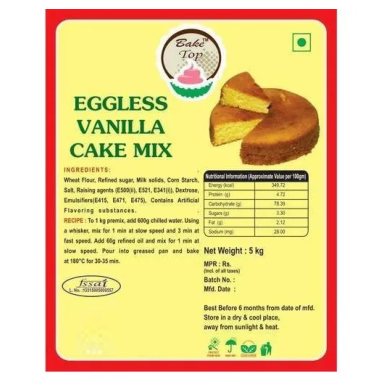

In [19]:
from google.colab import files

uploaded = files.upload()
for file_name in uploaded:
    label, probs = predict_image(file_name)
    print(f"\n{file_name} -> {label.upper()}")
    for name, p in zip(CLASS_NAMES, probs):
        print(f"  {name:<9} {p * 100:5.1f}%")
    plt.imshow(Image.open(file_name))
    plt.axis("off")
    plt.show()

## If accuracy is below 80%

Try these in order, and only look at the test set once at the end:

1. Raise `pca_components` from 256 to 512 (section 5).
2. SVM `C` from 1 to 3, KNN `n_neighbors` from 15 to 7 (section 6).
3. Improve the OCR: sharpen or threshold the image in `read_text`.
4. Average the features of each image and its horizontal flip in the CNN extractors.

Remember to delete the saved `.npy` files if you change anything in the extraction steps.